# 04 · El segundo alelo ausente

> **Saneado:** sin coordenadas ni identidad de variantes. El locus se describe por tamaño y
> por posición relativa.

## Pregunta biológica

Si el análisis estándar encuentra **un solo** alelo claramente patogénico en un gen de MVA, el
segundo puede ser una variante **reguladora**, **intrónica profunda** o **estructural**.

**¿Existe un segundo alelo que nuestro pipeline codificante no ve?**

## Hipótesis y preregistro

`docs/DECISIONS.md` § *Hidden Second Allele*. Ventana: cuerpo del gen ± ~100 kb, porque **hay
precedente humano publicado** de un segundo alelo regulador decenas de kb aguas arriba;
restringirse al cuerpo del gen sería conceptualmente incorrecto.

Orden de matanza, del filtro barato al caro:
`frecuencia → calidad → posición funcional → conservación y regulación → AlphaGenome`

**La predicción #4 decía que AlphaGenome daría Δ plano — y se escribió queriendo fallarla**,
para que un negativo fuera reportable en vez de decepcionante.

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # el pipeline usa rutas relativas a la raiz
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # figuras inline + caption con procedencia
print("entorno listo · las figuras de este notebook aparecen INLINE, con caption")

entorno listo · las figuras de este notebook aparecen INLINE, con caption


## Método · el funnel del locus

In [2]:
LOCUS = [
    ("variantes en el locus ampliado (~270 kb)", 321),
    ("tras filtro de frecuencia poblacional",     4),
    ("raras y de calidad, posicion funcional",    1),
    ("enviadas a AlphaGenome",                    1),
    ("con delta relevante",                       0),
]
for n, v in LOCUS:
    print(f"  {n:<44}{v:>6}")
print()
print("  La prediccion #1 fallo por lo alto: se esperaban 800-2000 variantes y hubo 321.")
print("  Se registra como fallo de calibracion de la prediccion, no como resultado.")

  variantes en el locus ampliado (~270 kb)       321
  tras filtro de frecuencia poblacional            4
  raras y de calidad, posicion funcional           1
  enviadas a AlphaGenome                           1
  con delta relevante                              0

  La prediccion #1 fallo por lo alto: se esperaban 800-2000 variantes y hubo 321.
  Se registra como fallo de calibracion de la prediccion, no como resultado.


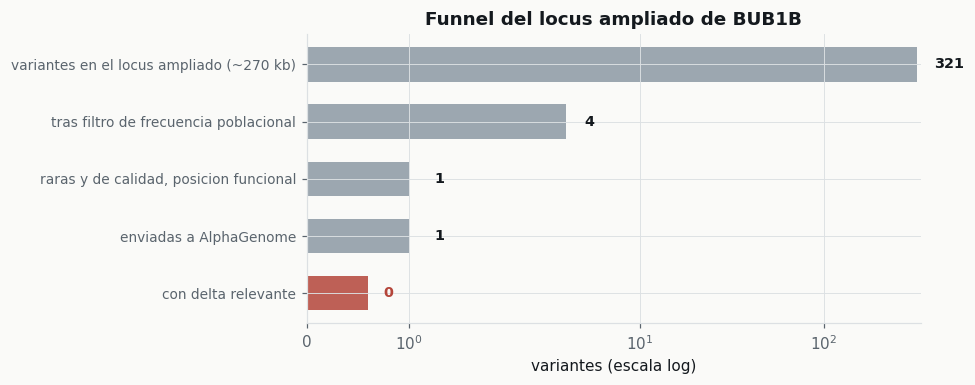

> **Figura principal 1 · el funnel del locus**  
> `EXP-008` · **MEASURED+DERIVED**  
> *Qué enseña:* de 321 variantes en 270 kb, una sola sobrevivio a frecuencia, calidad y posicion funcional: una intronica profunda ausente de gnomAD, sin rsID, PASS, heterocigota, a mas de 1 kb del borde de exon mas cercano.  
> **Qué NO demuestra:** que no exista un segundo alelo. Este funnel solo cubre SNV e indel dentro de la ventana: no ve variantes estructurales, que son EXP-012 y estan bloqueadas.  
> procedencia: `docs/DECISIONS.md § Hidden Second Allele`

In [3]:
fig, ax = plt.subplots(figsize=(9.0, 3.6))
names = [s[0] for s in LOCUS][::-1]
vals = [s[1] for s in LOCUS][::-1]
mx = max(vals)
cols = [fl.DEAD if v == 0 else fl.FLOW for v in vals]
ax.barh(range(len(names)), [max(v, 0.6) for v in vals], color=cols, alpha=0.85, height=0.6)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=9)
ax.set_xscale("symlog"); ax.set_xlabel("variantes (escala log)")
for i, v in enumerate(vals):
    ax.text(max(v, 0.6) * 1.25, i, str(v), va="center", fontsize=9.4, fontweight="bold",
            color=fl.DEAD if v == 0 else fl.INK)
ax.set_title("Funnel del locus ampliado de BUB1B")

fl.done(fig, "Figura principal 1 · el funnel del locus", "EXP-008", "MEASURED+DERIVED",
        "de 321 variantes en 270 kb, una sola sobrevivio a frecuencia, calidad y posicion "
        "funcional: una intronica profunda ausente de gnomAD, sin rsID, PASS, heterocigota, "
        "a mas de 1 kb del borde de exon mas cercano.",
        "que no exista un segundo alelo. Este funnel solo cubre SNV e indel dentro de la "
        "ventana: no ve variantes estructurales, que son EXP-012 y estan bloqueadas.",
        prov="docs/DECISIONS.md § Hidden Second Allele")

## Resultado primario · AlphaGenome sobre el único candidato

Las pistas que se dibujan **se congelaron antes** de repetir la llamada, para que no se
pudieran elegir las más favorecedoras después de verlas. Y las reglas de dibujo también: REF y
ALT comparten escala Y, y el Δ va en su propio carril con el cero visible.

**Fue la única transmisión de un dato del paciente fuera de la máquina en todo el proyecto**,
prevista en `docs/03_ALPHAGENOME_ASSESSMENT.md` §7. Se envió la shortlist, nunca el VCF.

In [4]:
import glob
AG = glob.glob("work/alphagenome/chr*_A_G.json")[0]      # ruta no impresa: lleva coordenada
ag = json.load(io.open(AG, encoding="utf-8"))
mods = ag["modalities"]
print(f"  estado de la llamada: {ag.get('status')}  ·  ventana: {ag.get('window_bp'):,} pb")
print()
print(f"  {'modalidad':<22}{'pistas':>8}{'delta rel %':>14}{'delta local max':>18}")
for m in sorted(mods, key=lambda x: -abs(x["delta_rel"])):
    print(f"  {m['modalidad']:<22}{m['pistas']:>8}{m['delta_rel']:>14.3f}"
          f"{m['delta_local_max']:>18.4f}")
peor = max(abs(m["delta_rel"]) for m in mods)
spl = [m for m in mods if "splic" in m["modalidad"]]
print()
print(f"  mayor delta relativo de cualquier modalidad : {peor:.2f} %")
if spl:
    print(f"  delta LOCAL de junciones de splicing        : "
          f"{min(m['delta_local_max'] for m in spl):.4f}")

  estado de la llamada: PREDICTED  ·  ventana: 1,048,576 pb

  modalidad               pistas   delta rel %   delta local max
  rna_seq                    667         0.034            0.1562
  chip_tf                   1617         0.022           96.0000
  dnase                      305         0.019            0.7500
  chip_histone              1116         0.018           16.0000
  atac                       167         0.013            0.1875
  splice_site_usage          734         0.012            0.0039
  splice_sites                 4         0.008            0.0063
  splice_junctions           367         0.004            0.0000

  mayor delta relativo de cualquier modalidad : 0.03 %
  delta LOCAL de junciones de splicing        : 0.0000


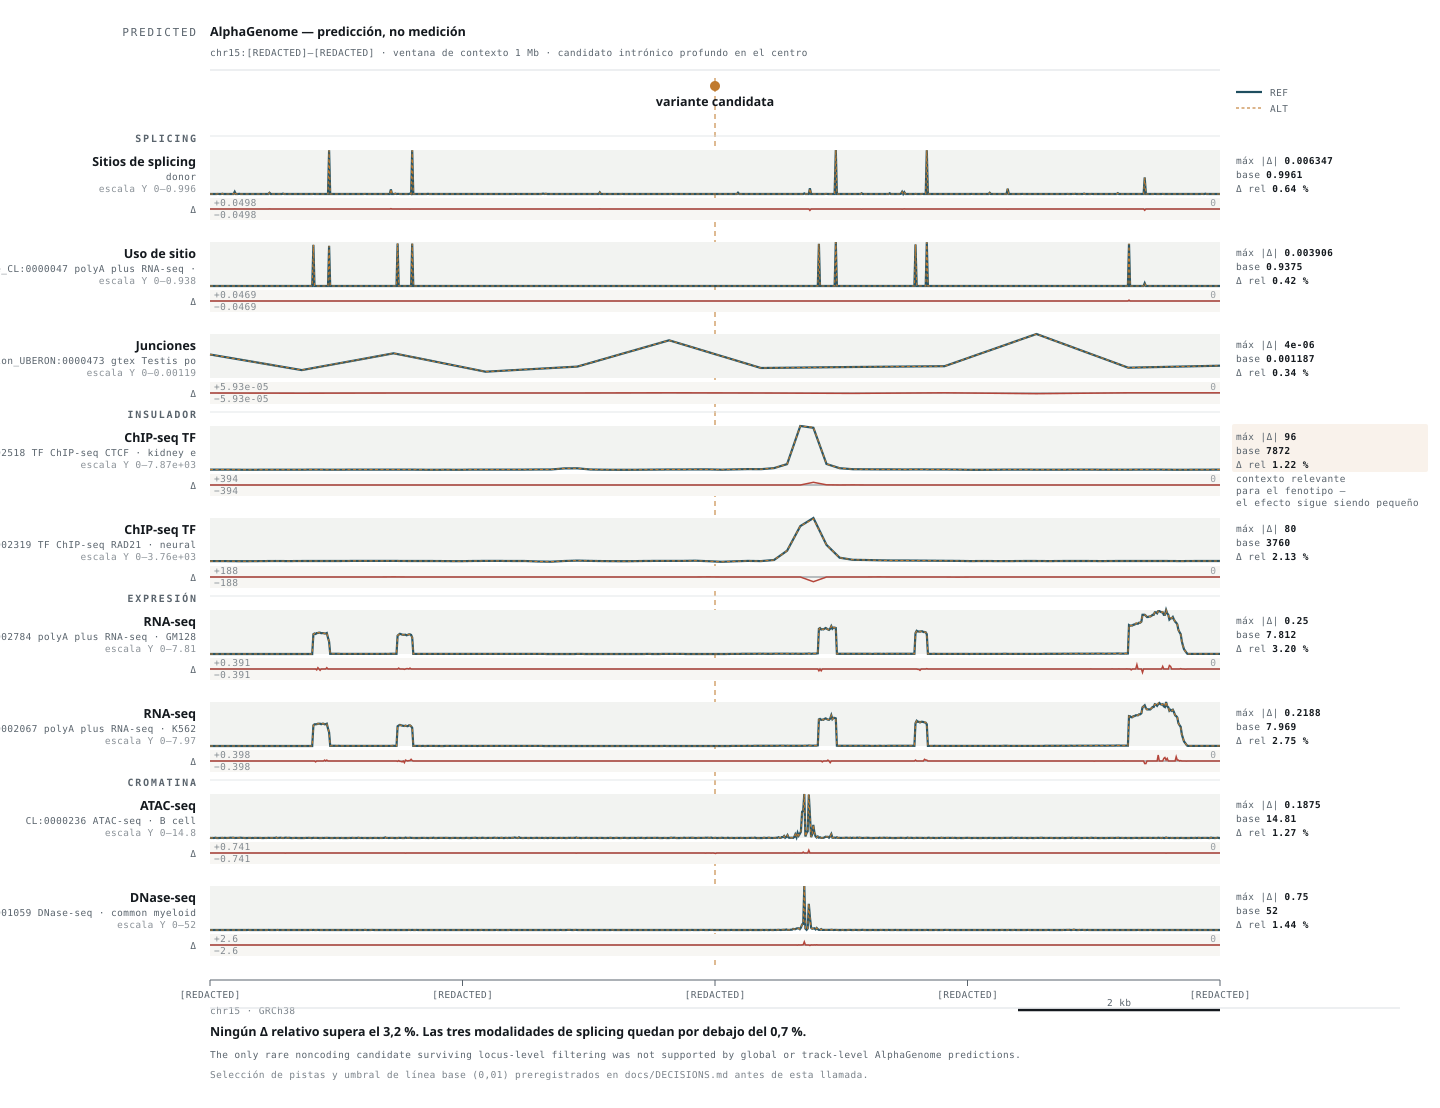

> **Figura principal 2 · AlphaGenome REF / ALT / delta**  
> `EXP-009` · **PREDICTED**  
> *Qué enseña:* REF y ALT practicamente identicos, y el carril delta plano en el cero. Las tres modalidades de splicing por debajo del 1,2 %, con el delta local de junciones en 0,0000. El control de sanidad paso: las medias REF y ALT son NO triviales, asi que el delta plano es un RESULTADO, no una llamada fallida.  
> **Qué NO demuestra:** que AlphaGenome demuestre que no existe un segundo alelo. Solo dice que NO APOYA el unico candidato SNV/indel que encontramos. Ademas el resumen agrega miles de pistas: un efecto fuerte en un solo tejido podria diluirse — el argumento que no depende de ese promedio es el splicing, cuyo delta local es cero.  
> procedencia: `src/make_fig5.py → fig5_alphagenome.svg · sha256[:12]=d9378c8e89c3`

In [5]:
fl.svg("figures/fig5_alphagenome.svg",
       "Figura principal 2 · AlphaGenome REF / ALT / delta",
       "EXP-009", "PREDICTED",
       "REF y ALT practicamente identicos, y el carril delta plano en el cero. Las tres "
       "modalidades de splicing por debajo del 1,2 %, con el delta local de junciones en "
       "0,0000. El control de sanidad paso: las medias REF y ALT son NO triviales, asi que "
       "el delta plano es un RESULTADO, no una llamada fallida.",
       "que AlphaGenome demuestre que no existe un segundo alelo. Solo dice que NO APOYA el "
       "unico candidato SNV/indel que encontramos. Ademas el resumen agrega miles de pistas: "
       "un efecto fuerte en un solo tejido podria diluirse — el argumento que no depende de "
       "ese promedio es el splicing, cuyo delta local es cero.",
       generator="src/make_fig5.py")

### Control de robustez · se revisaron las pistas individuales

Para descartar que un efecto específico de tejido se estuviera diluyendo en el agregado:

- **El top por cambio relativo es ruido.** Las líneas base locales son ~0,0001–0,005; un 5 %
  sobre cero es división por un número minúsculo.
- **El top por cambio absoluto** son pistas de CTCF y RAD21, con cambios del 1,2–2,3 % sobre
  líneas base de 1 400–7 900. Nada funcionalmente interpretable.
- **Sin coherencia biológica**: los tejidos del top son un surtido disperso. No hay señal renal
  ni hematopoyética.

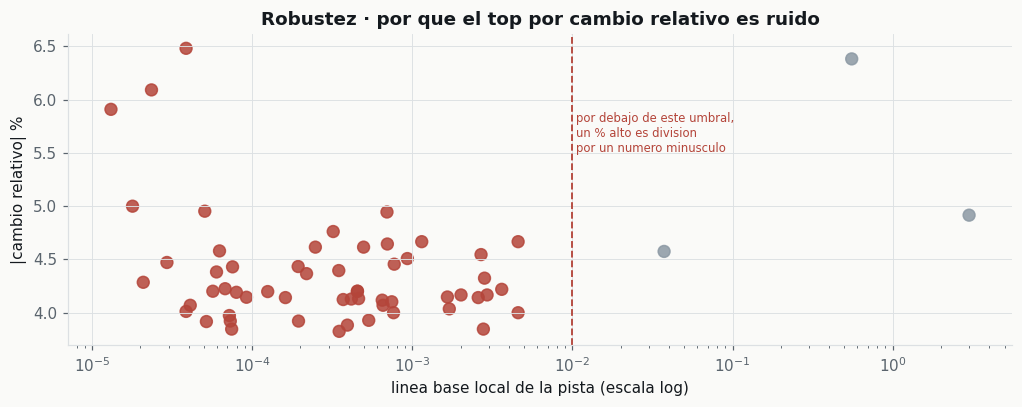

> **Figura de robustez · el % relativo enganya cuando la base es cero**  
> `EXP-009` · **PREDICTED**  
> *Qué enseña:* cada punto es una de las pistas con mayor cambio relativo. Las que producen porcentajes grandes tienen lineas base proximas a cero: el porcentaje es un artefacto de la division, no senal.  
> **Qué NO demuestra:** que no exista efecto en ningun tejido. Es un argumento sobre la METRICA, no una busqueda exhaustiva por tejido.  
> procedencia: `work/alphagenome/*_tracks.json`

In [6]:
TR = glob.glob("work/alphagenome/chr*_tracks.json")[0]
tr = json.load(io.open(TR, encoding="utf-8"))
top = [t for t in tr.get("top_rel", []) if t.get("rloc")]
if top:
    fig, ax = plt.subplots(figsize=(9.4, 3.8))
    rels = [abs(t["rel"]) * 100 for t in top]
    bases = [t["rloc"] for t in top]
    ax.scatter(bases, rels, s=60, c=[fl.DEAD if b < 0.01 else fl.FLOW for b in bases],
               alpha=0.85)
    ax.set_xscale("log"); ax.set_xlabel("linea base local de la pista (escala log)")
    ax.set_ylabel("|cambio relativo| %")
    ax.axvline(0.01, color=fl.DEAD, ls="--", lw=1.2)
    ax.text(0.0105, max(rels) * 0.85, "por debajo de este umbral,\nun % alto es division\npor "
            "un numero minusculo", fontsize=7.6, color=fl.DEAD)
    ax.set_title("Robustez · por que el top por cambio relativo es ruido")
    fl.done(fig, "Figura de robustez · el % relativo enganya cuando la base es cero",
            "EXP-009", "PREDICTED",
            "cada punto es una de las pistas con mayor cambio relativo. Las que producen "
            "porcentajes grandes tienen lineas base proximas a cero: el porcentaje es un "
            "artefacto de la division, no senal.",
            "que no exista efecto en ningun tejido. Es un argumento sobre la METRICA, no una "
            "busqueda exhaustiva por tejido.",
            prov="work/alphagenome/*_tracks.json")
else:
    print("  sin pistas individuales en el fichero; el argumento queda en el texto")

## Decisión

| Rama | Estado |
|---|---|
| **Segundo alelo SNV/indel regulador** | **NEGATIVE** en el alcance evaluado |
| **Segundo alelo estructural (SV/CNV)** | **BLOCKED** — falta BAM/CRAM de profundidad completa |

**La formulación exacta:** *No candidate survived population filtering plus global and
track-level AlphaGenome interrogation.*

**No:** «AlphaGenome demostró que no existe un segundo alelo».

### Sobre la CNV grande

Desde la profundidad y la heterocigosidad del VCF: la región no muestra pérdida de
heterocigosidad ni caída de profundidad — se observa lo contrario. Pero **la profundidad del
VCF no está normalizada para llamar número de copia**, así que lo defendible es *no evidence
for a large heterozygous deletion*, no «CNV descartada».

**Sigue sin resolverse:** CNV pequeñas que quepan entre variantes, eventos equilibrados que no
cambian número de copia, inserciones, y todo lo local a un punto de rotura.

### Falsificador

BAM/CRAM de los cuatro carriles → llamado de SV con pares discordantes y *split reads*.
**Prohibido cerrar un negativo estructural con L001**: un carril a ~13× es piloto, no ausencia.

### Siguiente experimento

`05_RESIDUAL_PHENOTYPE` — si el segundo alelo no aparece, ¿y si parte del fenotipo no es de
`BUB1B`?